In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

In [2]:
import json

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

# TODO:
1. Wikipedia harvest - Run as is for now, try to understand why it crushes near the end. **---------> DONE!**
2. Extract tables:
    - length between 3 to 10 **---------> DONE!**
    - table is square and parsed normally (no merged cells) **---------> DONE!**
    - full table **---------> DONE!**
    - remove some columns with no relevant data (empty or by keywords) **---------> DONE!**
3. Add to table extraction text titles and relevant paragraphs for the context. **---------> DONE!**
4. Cluster titles to remove similar options + take only one table per page. **---------> DONE!**
5. Create groups - all the table, try to see what is the main entity - return the column name, if they don't have one, discard the table and return 'None'. **---------> DONE!**
6. Create Questions
    - strategy injection, sample a subset of strategies in a shuffled order, if not possible than discard table.
    - make a function to extract the answer per question strategy --> create GT answer.
    - Add the 'group size' strategy.
    - constract the data samples.

### Havest Wikipedia pages with tables:

In [91]:
from knowledge_maze.create_dataset.create_questions.wikipedia_mining import WikiHarvester
# Initialize Wikipedia harvester
harvester = WikiHarvester()
# Run Phase 1 - Harvesting titles based on keywords
harvester.run_complete_harvest()
# Run Phase 2 - Filtering pages for tables
await harvester.filter_pages_async()

Harvesting Pages By Keywords:   0%|          | 0/233 [00:00<?, ?keyword/s]


TOTAL UNIQUE TITLES COLLECTED: 167913



Method,Keyword,Count
Prefix,List of cities,1537
Prefix,List of countries,1278
Prefix,List of towns,501
Prefix,List of villages,483
Prefix,List of districts,375
Prefix,List of municipalities,1021
Prefix,List of communes,194
Prefix,List of counties,259
Prefix,List of provinces,84
Prefix,List of territories,22


Filtering Pages with Tables:   0%|          | 0/167913 [00:00<?, ?page/s]


TOTAL PAGES WITH TABLES COLLECTED: 62306



In [93]:
save_json("table_titles", harvester.valid_titles)

In [3]:
table_titles = load_json("C:/Users/Daniel/Desktop/KnowledgeMaze/data_files/table_titles.json")

### Parse and filter Wikipedia tables:

In [4]:
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor

extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(table_titles)

Pre-processing: cluster similar pages and discard similarities ---> 6426 pages discarded.


Extracting Tables:   0%|          | 0/55880 [00:00<?, ?Page/s]

Starting Extraction: 55880 titles | Async Limit: 20 | CPU Workers: 19
TOTAL PAGES WITH VALID TABLES: 37946 OUT OF 55880 (67.9%)


In [5]:
validated_tables = load_jsonl(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))

In [70]:
from knowledge_maze.create_dataset.create_questions.table_processing import TablePostProcessor

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
cleaned_data = processor.process()

Selecting Best Tables: 100%|█████████████████████████████████████████████████| 17442/17442 [00:00<00:00, 717648.13it/s]


════════════════════════════════════════════
📊 TABLE PROCESSING SUMMARY (Limit: 12)
════════════════════════════════════════════
Total tables scanned:      126924
Dropped (Single Col):      577
Dropped (Bad Headers):     9813
Dropped (Cell too long):   2682
Short tables found:        38679
Unique source pages:       17442
Final sampled (1/page):    17442
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE TABLES ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------


═════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════

,Rank,Division,Gold,Silver,Bronze,Total
0,1,New England,4,5,1,10
1,2,Alaska,2,5,3,10
2,3,Intermountain,3,1,1,5
3,4,Pacific Northwest,2,0,2,4
4,5,Rocky Mountain,0,1,2,3
5,6,Far West*,0,0,1,1
6,7,Great Lakes,0,0,1,1
7,8,Midwest,0,0,1,1
8,9,High Plains,0,0,0,0
9,10,Mid-Atlantic,0,0,0,0



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
List of phobias > Psychological conditions > G
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Phobia,Condition
0,Galeophobia,fear of sharks
1,Gamophobia,fear of marriage
2,Gelotophobia,fear of being laughed at
3,Gephyrophobia,fear of bridges
4,"Genophobia , coitophobia",fear of sexual intercourse
5,Genuphobia,fear of knees or the act of kneeling
6,Gerascophobia,fear of growing old or aging
7,Gerontophobia,"fear of growing old, or a hatred or fear of th..."
8,Globophobia,fear of balloons
9,Glossophobia,fear of speaking in public or of trying to speak



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
List of members of the parliament of Malta, 2017–2022 > List by office
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Office,Officeholder,Year,Political party
0,President of Malta,Marie-Louise Coleiro Preca,2014–2019,Partit Laburista
1,President of Malta,George Vella,2019–present,Partit Laburista
2,Prime Minister of Malta,Joseph Muscat,2013–2020,Partit Laburista
3,Prime Minister of Malta,Robert Abela,2020–present,Partit Laburista
4,Leader of Opposition,Adrian Delia,2017–2020,Partit Nazzjonalista
5,Leader of Opposition,Bernard Grech,2020–present,Partit Nazzjonalista
6,Speaker,Anġlu Farrugia,2013–present,Partit Laburista



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
List of adjectivals and demonyms of astronomical bodies > Moons (Saturn)
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Name,"Adjective, demonym"
0,Dione,Dionean
1,Enceladus,"Enceladean, Enceladan"
2,Hyperion,Hyperionian
3,Iapetus,"Iapetian, Japetian"
4,Mimas,"Mimantean, Mimantian"
5,Rhea,Rhean
6,Tethys,Tethyan
7,Titan,"Titanian / t aɪ ˈ t eɪ n i ə n / , Titanean"


### Create Potential Entity Groups:

In [159]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import TableGroupConstructor

group_constructor = TableGroupConstructor(random.sample(cleaned_data, 100))
await group_constructor.get_groups()

Creating groups based on the Wikipedia tables using LLM...


Usage cost: 0.0236$ (Estimated: 0.02$): 100%|████████████████████████████████████████| 100/100 [00:03<00:00, 26.06it/s]


════════════════════════════════════════════
📊 TABLE LLM GROUPING SUMMARY
════════════════════════════════════════════
Total tables scanned:      100
Total groups made:      91
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE Groups ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------


══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
--> Types of aircraft in the fleet of Brymon Airways.
--> Players who have won the IRB International U21 Player of the Year award from 2001 to 2006.
--> Flags used during

,Best Story (Original),Best Story (Adapted)
0,"Ishita Moitra , Shashank Khaitan , Sumit Roy –...","Vidhu Vinod Chopra , Jaskunwar Kohli – 12th Fail"
1,Best Screenplay,Best Dialogue
2,"Vidhu Vinod Chopra , Jaskunwar Kohli, Anurag P...",Ishita Moitra – Rocky Aur Rani Kii Prem Kahaani
3,Best Cinematography,Best Editing
4,G. K. Vishnu – Jawan,Sandeep Reddy Vanga – Animal
5,Best Background Score,Best Choreography
6,Harshavardhan Rameshwar – Animal,"Bosco–Caesar – "" Jhoome Jo Pathaan "" – Pathaan"
7,Best Sound Mixing,Best Sound Design
8,"Sampath Alwar, Chris Jacobson, Rob Marshall, M...","Sachin Sudhakaran, Hariharan M – Animal"
9,Best Special Effects,Best Special Effects



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
--> List of members of the European Parliament for the United Kingdom (2019–2020) > Changes in members or affiliation
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Members 1973–1979,(elected by parliament)
0,Members 1979–1984,( 1979 election )
1,Members 1984–1989,( 1984 election )
2,Members 1989–1994,( 1989 election )
3,Members 1994–1999,( 1994 election )
4,Members 1999–2004,( 1999 election )
5,Members 2004–2009,( 2004 election )
6,Members 2009–2014,( 2009 election )
7,Members 2014–2019,( 2014 election )
8,Members 2019–2020,( 2019 election )


### Create FanOut Questions out of the Entity Groups:

In [164]:
from knowledge_maze.create_dataset.create_questions.question_generation import QuestionGenerator

question_generator = QuestionGenerator(random.sample(group_constructor.valid_tables, 50))
await question_generator.generate_questions()

Usage cost: 0.0079$ (Estimated: 0.01$): 100%|██████████████████████████████████████████| 50/50 [00:04<00:00, 11.20it/s]


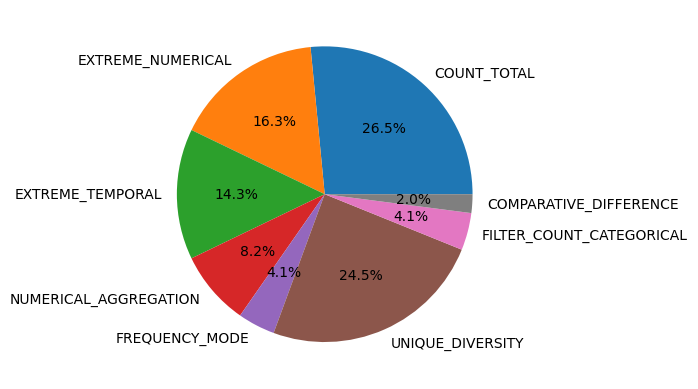

In [165]:
import matplotlib.pyplot as plt
from collections import Counter

def plot_categorical_pie(data):
    counts = Counter(data)
    plt.pie(counts.values(), labels=counts.keys(), autopct='%1.1f%%')

plot_categorical_pie([sample['Strategy'] for sample in question_generator.valid_tables])

In [167]:
for sample in question_generator.valid_tables:
    print(f"Group name: {sample['Group name']}")
    print(f"Strategy: {sample['Strategy']}")
    print(f"Question: {sample['Question']}")
    print(f"Entity column: {sample['Entity column']}")
    print(f"Data column: {sample['Data column']}")
    print(f"Wikipedia page: {sample['Wikipedia page']}")
    display(pd.DataFrame(sample['Table data']))
    print()
    print()

Group name: Players who have scored the most runs in Twenty20 International matches for the Eswatini national cricket team.
Strategy: COUNT_TOTAL
Question: How many players have scored runs for the Eswatini national cricket team in Twenty20 International matches?
Entity column: Player
Data column: Player
Wikipedia page: https://en.wikipedia.org/wiki/Eswatini_national_cricket_team#Records_and_statistics


,Player,Runs,Average,Career span
0,Adil Butt,823,34.29,2022–2025
1,Haris Rashid,239,14.05,2022–2025
2,Tarun Sandeep,344,28.66,2022–2024
3,Christiaan Forbes,190,13.57,2021–2023
4,Hujeifa Jangariya,190,31.66,2023–2025




Group name: Highest-grossing Japanese films released in 1999.
Strategy: EXTREME_NUMERICAL
Question: Which film released in 1999 grossed the highest revenue at the box office in Japan?
Entity column: Title
Data column: Gross
Wikipedia page: https://en.wikipedia.org/wiki/List_of_Japanese_films_of_1999#Highest-grossing_films


,Rank,Title,Gross
0,1,Pokémon: The Movie 2000,¥3.50 billion
1,2,Ring 2,¥2.10 billion
2,3,Poppoya,¥2.05 billion
3,4,Doraemon: Nobita Drifts in the Universe,¥2.00 billion
4,5,Case Closed: The Last Wizard of the Century,¥1.45 billion




Group name: Holes on the scorecard of Shinnecock Hills Golf Club, including their names and yardages.
Strategy: EXTREME_NUMERICAL
Question: Which hole on the scorecard of Shinnecock Hills Golf Club has the longest yardage?
Entity column: Hole
Data column: Yards
Wikipedia page: https://en.wikipedia.org/wiki/Shinnecock_Hills_Golf_Club#Scorecard


...

,Language,Usual residents aged 3+,Proportion
0,English only,496027,86.62%
1,Gaelic,2305,0.40%
2,Scots,2826,0.49%
3,British Sign Language,1717,0.30%
4,Polish,7379,1.29%
5,Other,62379,10.89%




Group name: Mayors of Rimini, Italy since 1946, elected directly since 1995.
Strategy: EXTREME_TEMPORAL
Question: Who was the first mayor of Rimini, Italy, elected directly since 1995?
Entity column: Took office
Data column: Took office
Wikipedia page: https://en.wikipedia.org/wiki/List_of_mayors_of_Rimini#Republic_of_Italy


,Took office,Left office,Party,Coalition
0,Giuseppe Chicchi (b. 1944),9 May 1995,29 June 1999,PDS
1,Alberto Ravaioli (b. 1945),29 June 1999,11 January 2001,DL PD
2,Alberto Ravaioli (b. 1945),28 May 2001,30 May 2006,DL PD
3,Alberto Ravaioli (b. 1945),30 May 2006,31 May 2011,DL PD
4,Andrea Gnassi (b. 1969),31 May 2011,8 June 2016,PD
5,Andrea Gnassi (b. 1969),8 June 2016,7 October 2021,PD
6,Jamil Sadegholvaad (b. 1972),7 October 2021,Incumbent,PD




Group name: Players who have won the IRB International U21 Player of the Year award from 2001 to 2006.
Strategy: UNIQUE_DIVERSITY
Question: How many different countries are represented by the winners of the IRB International U21 Player of the Year award from 2001 to 2006?
Entity column: Winner
Data column: Country
Wikipedia page: https://en.wikipedia.org/wiki/IRB_International_U21_Player_of_the_Year#List_of_winners


,Year,Winner,Country
0,2001,Richie McCaw,New Zealand
1,2002,Pat Barnard,South Africa
2,2003,Ben Atiga,New Zealand
3,2004,Jerome Kaino,New Zealand
4,2005,Tatafu Polota-Nau,Australia
5,2006,Lionel Beauxis,France


In [124]:
def filter_tables_by_noise(tables):
    """
    Filters a list of tables to find those containing 'total' in values
    or rows with identical values across all columns.
    """
    suspicious_tables = []

    for table in tables:
        rows = table.get('Table data', [])
        found_noise = False
        
        for row in rows:
            values = list(row.values())
            
            # 1. Check for 'total' in any value (case-insensitive)
            if any("total" in str(v).lower() for v in values):
                found_noise = True
                break
            
            # 2. Check if all values in the row are exactly the same
            # (Ensuring row has more than 1 column to avoid false positives)
            if len(values) > 1 and len(set(values)) == 1:
                found_noise = True
                break
        
        if found_noise:
            suspicious_tables.append(table)
            
    return suspicious_tables

In [125]:
sus_tables = filter_tables_by_noise(group_constructor.valid_tables)
print(len(sus_tables))

153


In [121]:
for sus in sus_tables:
    print(f"Group name: {sus['Group name']}")
    print(f"Entity column: {sus['Entity column']}")
    display(pd.DataFrame(sus['Table data']))

Group name: Live albums released by Bob Marley and the Wailers.
Entity column: Title


,Title,Album details,Peak chart positions,Certifications ( sales thresholds )
0,AUS,NZ,SWE,SWI
1,Live!,Released: 5 December 1975 Labels: Island / Tuf...,51,—
2,Babylon by Bus,Released: 10 November 1978 Labels: Island/Tuff...,34,21
3,Talkin' Blues,Released: 4 February 1991 Labels: Island/Tuff ...,—,30
4,Live at the Roxy,Released: 24 June 2003 Labels: Island/Tuff Gon...,—,—
5,"Live Forever: September 23, 1980 • Stanley The...",Released: 2011 Labels: Island/Tuff Gong Format:,—,—
6,Easy Skanking in Boston '78,Released: 2015 Labels: Island/Tuff Gong Format:,—,—
7,"Live at the Rainbow, 1st June 1977",Released: 12 June 2020 Labels: Tuff Gong Forma...,—,—
8,"Live at the Rainbow, 2nd June 1977",Released: 12 June 2020 Labels: Tuff Gong Forma...,—,—
9,"Live at the Rainbow, 3rd June 1977",Released: 12 June 2020 Labels: Tuff Gong Forma...,—,—


Group name: Tournament performance records of the Sápmi football team in the VIVA World Cup and ConIFA World Football Cup.
Entity column: Year


,Year,Position,GP,W,D,L,GS,GA
0,VIVA World Cup,VIVA World Cup,VIVA World Cup,VIVA World Cup,VIVA World Cup,VIVA World Cup,VIVA World Cup,VIVA World Cup
1,2006,Champion,3,3,0,0,41,1
2,2008,Third place,5,2,1,2,9,8
3,2009,Third place,4,1,1,2,12,12
4,2010,did not enter,did not enter,did not enter,did not enter,did not enter,did not enter,did not enter
5,2012,did not enter,,,,,,
6,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup,ConIFA World Football Cup
7,2014,Group stage,4,1,0,3,6,10
8,2016,Quarter-finals,5,3,0,2,10,4
9,2018,did not qualify,did not qualify,did not qualify,did not qualify,did not qualify,did not qualify,did not qualify


Group name: International athletic competitions participated in by Alejandro Herrera, focusing on his performances in the triple jump and long jump events.
Entity column: Competition


...

,Race and ethnicity,Total
0,White,48%
1,Black,27%
2,Asian,9%
3,Hispanic,8%
4,Two or more races,5%
5,International student,2%
6,Unknown,1%
7,Economic diversity,Economic diversity
8,Low-income,34%
9,Affluent,66%


Group name: International athletic competitions in which Krzysztof Krawczyk represented Poland and his positions in those events.
Entity column: Competition


,Year,Competition,Venue,Position,Notes
0,Representing Poland,Representing Poland,Representing Poland,Representing Poland,Representing Poland
1,1981,European Indoor Championships,"Grenoble, France",6th,2.19 m
2,1981,European Junior Championships,"Utrecht, Netherlands",1st,2.26 m
3,1984,European Indoor Championships,"Gothenburg, Sweden",12th,2.15 m
4,1985,World Indoor Games,"Paris, France",7th,2.21 m
5,1986,European Indoor Championships,"Madrid, Spain",6th,2.24 m
6,1986,European Championships,"Stuttgart, West Germany",5th,2.28 m
7,1987,European Indoor Championships,"Liévin, France",8th,2.24 m
8,1987,Universiade,"Zagreb, Yugoslavia",6th,2.24 m
9,1987,World Championships,"Rome, Italy",12th,2.24 m


Group name: Opponents faced by the Australia women's national cricket team in Twenty20 Internationals along with match results.
Entity column: Opponent


,Opponent,Mat,Won,Lost,Tied,NR,First match,First win
0,ICC Full members,ICC Full members,ICC Full members,ICC Full members,ICC Full members,ICC Full members,ICC Full members,ICC Full members
1,Bangladesh,5,5,0,0,0,27 February 2020,27 February 2020
2,Barbados,1,1,0,0,0,31 July 2022,31 July 2022
3,England,45,23,21,0,1,2 September 2005,2 September 2005
4,India,35,26,8,0,1,28 October 2008,28 October 2008
5,Ireland,8,8,0,0,0,27 March 2014,27 March 2014
6,New Zealand,55,33,21,0,1,18 October 2006,19 July 2007
7,Pakistan,16,14,0,0,2,29 September 2012,29 September 2012
8,South Africa,11,9,2,0,0,7 May 2010,7 May 2010
9,Sri Lanka,8,8,0,0,0,27 September 2016,27 September 2016


In [122]:
def test_noise_distribution(tables):
    stats = {"total_found": 0, "duplicates_found": 0, "both": 0}
    
    for table in tables:
        rows = table.get('Table data', []) or table.get('rows', [])
        has_total = False
        has_dup = False
        
        for row in rows:
            values = list(row.values())
            if not values: continue
            
            # Check 1: "Total" presence
            if any("total" in str(v).lower() for v in values):
                has_total = True
            
            # Check 2: Row redundancy (all values identical)
            if len(values) > 1 and len(set(values)) == 1:
                has_dup = True
        
        # Tallying the results
        if has_total and has_dup:
            stats["both"] += 1
        elif has_total:
            stats["total_found"] += 1
        elif has_dup:
            stats["duplicates_found"] += 1

    # Printing the summary
    width = 40
    print("\n" + "═" * width)
    print("🧹 NOISE DETECTION SUMMARY")
    print("═" * width)
    print(f"Tables with 'Total':      {stats['total_found']}")
    print(f"Tables with Duplicates:   {stats['duplicates_found']}")
    print(f"Tables with BOTH:         {stats['both']}")
    print("─" * width)
    print(f"Total Noisy Tables:       {sum(stats.values())}")
    print("═" * width + "\n")

    return stats

In [123]:
test_noise_distribution(group_constructor.valid_tables)


════════════════════════════════════════
🧹 NOISE DETECTION SUMMARY
════════════════════════════════════════
Tables with 'Total':      85
Tables with Duplicates:   64
Tables with BOTH:         4
────────────────────────────────────────
Total Noisy Tables:       153
════════════════════════════════════════



{'total_found': 85, 'duplicates_found': 64, 'both': 4}